# Phase 1: Supervised Learning — Customer Churn

## 1. Model Selection & Rationale

### 1.1 Problem Type and Dataset Summary
We are predicting whether a customer will churn. This is a binary classification task (`churn_flag`: 1 = churned, 0 = retained).

The dataset has 100,000 rows and 18 columns. We removed `customer_id` because it is only an identifier. We also removed `churn_risk` because it is built from the target. High always means churned and Low always means retained, so keeping it would leak the answer. That leaves 15 predictors: 10 numeric and 5 categorical.

Part A found no missing values. The classes are fairly balanced: 46.22% churned and 53.78% retained.

### 1.2 Logistic Regression

We chose Logistic Regression as our baseline model because it is simple, interpretable, and suitable for binary classification. It estimates the probability that a customer will churn.

Our Part A analysis supports this choice. `recency_days` has a strong correlation with churn (r = 0.77), and the classes are fairly balanced. The dataset is also large enough to train the model reliably.

Logistic Regression has some limitations. It assumes a linear relationship between the features and the log-odds of churn, so it may miss non-linear patterns and interactions. Some features are skewed (such as `total_spent`), while others may be highly correlated (such as `purchase_frequency` and `website_visits`), which can affect coefficient stability.

We use StandardScaler to standardize numerical features and help the model train more consistently. We will compare Logistic Regression with Random Forest to see whether a more flexible model performs better.
### 1.3 Random Forest Classifier
We chose Random Forest to test whether a more flexible model does better. It can learn non-linear patterns and feature interactions, and it works well with a mix of numeric and categorical features. It does not need scaling and is not sensitive to skewed features.

It also gives feature importance scores, which helps us see which factors drive churn.

The trade-off is that it is harder to explain than Logistic Regression and slower to train.

### 1.4 Why This Pair
Logistic Regression is the simple, interpretable baseline. Random Forest is the flexible model. We will compare them on the same data split with the same metrics. This will show whether the extra complexity is worth it for this problem.

## 2. Implementation & Training Code

In [3]:
import pandas as pd

# Load the training and testing datasets
train = pd.read_csv("Dataset/Processed/train_selected.csv")
test = pd.read_csv("Dataset/Processed/test_selected.csv")

# Display dataset dimensions
print("Training data:", train.shape)
print("Testing data:", test.shape)

# Preview the training data
train.head()

Training data: (80000, 16)
Testing data: (20000, 16)


,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_flag
0,18-24,Other,Central,Loyal,Online,2,126.19,245.11,16,14,0.34,0.59,0.39,53,60.0,0
1,18-24,Female,East,New,In-Store,12,139.69,1655.39,33,58,0.46,0.34,0.11,84,61.5,0
2,55+,Other,West,VIP,Online,8,65.20,620.69,136,40,0.52,0.80,0.37,10,71.5,0
3,25-34,Female,Central,Returning,Online,5,162.94,905.68,201,26,0.63,0.66,0.52,32,57.0,1
4,25-34,Other,North,Returning,In-Store,1,31.82,34.56,116,7,0.32,0.89,0.56,14,66.5,0


In [4]:
# Separate features and target

X_train = train.drop(columns=["churn_flag"])
y_train = train["churn_flag"]

X_test = test.drop(columns=["churn_flag"])
y_test = test["churn_flag"]

# Display the dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (80000, 15)
y_train: (80000,)
X_test: (20000, 15)
y_test: (20000,)


In [5]:
print("Features used for training:")
print(X_train.columns.tolist())

Features used for training:
['age_group', 'gender', 'region', 'customer_segment', 'preferred_channel', 'purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build the Logistic Regression pipeline
lr_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Logistic Regression pipeline created successfully!")

Categorical features: 5
Numerical features: 10
Logistic Regression pipeline created successfully!


In [7]:
# Train the Logistic Regression model
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [8]:
# Predict customer churn using the test data
y_pred = lr_pipeline.predict(X_test)

# Display the first 10 predictions
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.iloc[:10].values)

Predicted: [1 0 0 0 0 1 1 1 0 0]
Actual:    [1 0 0 0 0 1 1 1 0 0]


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict churn probabilities
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Logistic Regression - Baseline Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Logistic Regression - Baseline Results
Accuracy:  0.9459
Precision: 0.9419
Recall:    0.9410
F1-score:  0.9415
ROC-AUC:   0.9904


In [16]:
#Model 2 - Random Forest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Create preprocessing for random forest
rf_preprocessing = ColumnTransformer(
    transformers=[
        ("num","passthrough", numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)

#Create Random Forest Pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", rf_preprocessing),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ]
)

#Train Random Forest model
rf_pipeline.fit(X_train,y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [17]:
#Model 2 - Random Forest

#Predict customer churn
rf_y_pred = rf_pipeline.predict(X_test)

#Display the first 10 predictions
print("Predicted:",rf_y_pred[:10])
print("Actual:",y_test.iloc[:10].values)

Predicted: [0 0 0 0 0 1 1 1 0 0]
Actual: [1 0 0 0 0 1 1 1 0 0]


In [18]:
#Model 2 - Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predicted probabilities
rf_y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)

# Display results
print("Random Forest - Baseline Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Random Forest - Baseline Results
Accuracy: 0.9409
Precision: 0.9377
Recall: 0.9343
F1-score: 0.936
ROC-AUC: 0.9878


# 3. Hyperparameter Tuning Process & Results

In [10]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define hyperparameter values
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["lbfgs", "liblinear"]
}

# Define 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform Hyperparameter Tuning
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

# Display the results
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV F1-score: 0.9395


In [19]:
#Model 2 - Random Forest

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define hyperparameter
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5]
}

# Define 5-Fold Cross-Validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Create Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

# Run hyperparameter tuning
rf_grid_search.fit(X_train, y_train)

# Display results
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV F1-score:", round(rf_grid_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV F1-score: 0.9348


### Hyperparameter Tuning Discussion

#####Logistic Regression:
Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. The best parameters were C = 0.01 and solver = lbfgs, achieving a cross-validation F1-score of 0.9395.

The tuned Logistic Regression model achieved a test F1-score of 0.9409, compared with 0.9415 for the baseline model. The difference was small, indicating that tuning did not provide a meaningful improvement in test performance.

#####Random Forest:

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. The parameters n_estimator, max_depth, and min_sample_split were evaluated using F1-score as the selection metric

the best parameters were n_estimator=100, max_depth=None and min_sample_split=5,achieving a cross-validation F1-score of 0.9348

The tuned Random Forest model achieved a test F1-score of 0.9360, compared with 0.9360 for the baseline model. both scores were equal when rounded to 4-decimal places, indicating that tuning did not provide a meaningful improvement in test performance.

## 4. Evaluation Metrics & Visualizations

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get the best Logistic Regression model
best_lr_model = grid_search.best_estimator_

# Make predictions
y_pred_tuned = best_lr_model.predict(X_test)
y_prob_tuned = best_lr_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(y_test, y_prob_tuned)

# Display results
print("Logistic Regression - Tuned Results")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_roc_auc:.4f}")

Logistic Regression - Tuned Results
Accuracy:  0.9455
Precision: 0.9418
Recall:    0.9401
F1-score:  0.9409
ROC-AUC:   0.9904


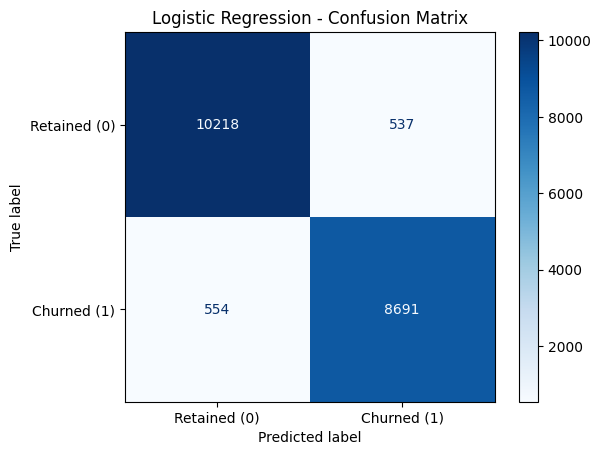

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

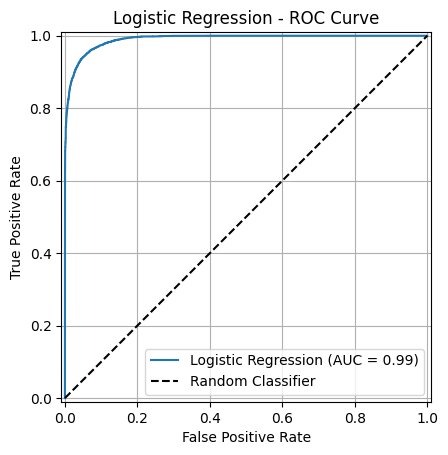

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Logistic Regression
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tuned,
    name="Logistic Regression"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Logistic Regression - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
#Model 2 - Random Forest

# Get the best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# Make predictions
rf_tuned_pred = rf_tuned_model.predict(X_test)
rf_tuned_prob = rf_tuned_model.predict_proba(X_test)[:, 1]

# Calculate metrics
rf_tuned_accuracy = accuracy_score(y_test, rf_tuned_pred)
rf_tuned_precision = precision_score(y_test, rf_tuned_pred)
rf_tuned_recall = recall_score(y_test, rf_tuned_pred)
rf_tuned_f1 = f1_score(y_test, rf_tuned_pred)
rf_tuned_roc_auc = roc_auc_score(y_test, rf_tuned_prob)

print("Random Forest - Tuned Results")
print("Accuracy:", round(rf_tuned_accuracy, 4))
print("Precision:", round(rf_tuned_precision, 4))
print("Recall:", round(rf_tuned_recall, 4))
print("F1-score:", round(rf_tuned_f1, 4))
print("ROC-AUC:", round(rf_tuned_roc_auc, 4))

Random Forest - Tuned Results
Accuracy: 0.9408
Precision: 0.9361
Recall: 0.9359
F1-score: 0.936
ROC-AUC: 0.9878


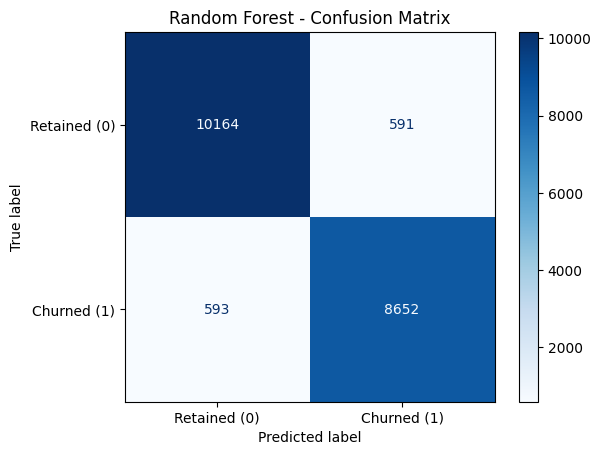

In [22]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_tuned_pred,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

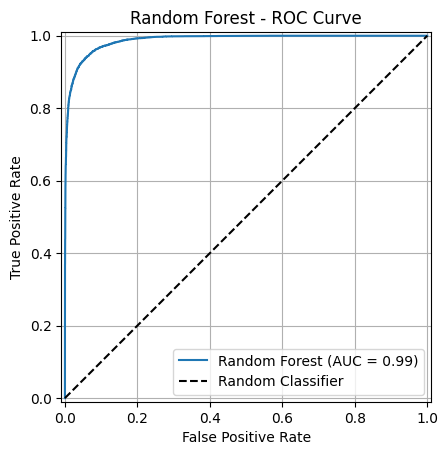

In [23]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Random Forest
RocCurveDisplay.from_predictions(
    y_test,
    rf_tuned_prob,
    name="Random Forest"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Random Forest - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

### Misclassification Analysis

The tuned **Logistic Regression** model incorrectly classified 1,091 out of 20,000 customers.

- False Positives (537): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (554): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.



The tuned **Random Forest** model misclassified 1,184 out of 20,000 customers.

- False Positives (591): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (593): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.

Compared with Logistic Regression, which misclassified 1,091 customers, Random Forest made 93 more classification errors.

For our customer retention system, reducing false negatives is valuable because identifying customers at risk of churn allows the business to take preventive actions.

### ROC Curve Analysis

Both Logistic Regression and Random Forest achieved high ROC-AUC scores, indicating strong ability to distinguish between churned and retained customers.

Logistic Regression achieved a ROC-AUC of 0.9904, slightly higher than Random Forest's 0.9878.


## 5. Model Comparison & Analysis

In [25]:
import pandas as pd

# Compare Logistic Regression with Random Forest
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ],
    "Random Forest": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ]

})

comparison

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.945450,0.940800
1,Precision,0.941808,0.936060
2,Recall,0.940076,0.935857
3,F1-score,0.940941,0.935958
4,ROC-AUC,0.990378,0.987829


##### Model Comparison & Analysis

The results show that both Logistic Regression and Random Forest achieved strong performance in predicting customer churn.

Logistic Regression slightly outperformed Random Forest across all five evaluation metrics. It achieved an accuracy of 0.9455 compared with 0.9408 for Random Forest, and a precision of 0.9418 compared with 0.9361.

Logistic Regression also achieved a higher recall of 0.9401 compared with 0.9359 for Random Forest.

In addition, Logistic Regression achieved an F1-score of 0.9409 and a ROC-AUC of 0.9904, compared with 0.9360 and 0.9878 for Random Forest, respectively.

Overall, the performance differences were relatively small, but Logistic Regression showed consistently better results on the test set.


## 6. Conclusion: Best Model Selection & Reasoning

Based on the evaluation results, Logistic Regression was selected as the best model for the customer churn prediction system.

The tuned Logistic Regression model achieved an F1-score of 0.9409 and a ROC-AUC of 0.9904, compared with 0.9360 and 0.9878 for the tuned Random Forest model. Logistic Regression also achieved higher accuracy, precision, and recall.

Additionally, Logistic Regression made fewer classification errors, misclassifying 1,091 customers compared with 1,184 for Random Forest. It also produced fewer false negatives (554 compared with 593), which is particularly valuable for identifying customers at risk of churn.


Although both models demonstrate a storng performance across all evaluation metrics , Logistic Regression achived slightely higher scores. Therefore, it was selected as the preferred model for predicting customer churn and supporting customer retention decisions.


## 7. Next Steps for Phase 2 Integration
In Phase 2, we will use the tuned Logistic Regression model as the core of our system. It gives each customer a churn probability, and it was our best model in Phase 1. We will use these probabilities to help the business decide which customers to contact first.

We plan to build on it in three ways:
- **Customer segments:** we will use clustering to group customers. These groups will add context to each prediction.
- **Dashboard:** we will show each customer's churn risk, the confidence of the prediction, and the main factors behind it. Logistic Regression coefficients make these factors easy to explain.
- **Generative AI:** we will turn the predictions into short, clear summaries for decision-makers.

Because the model still makes errors (1,091 out of 20,000 test customers), a person should review its recommendations before any action is taken. We also need to monitor the model over time, because customer behaviour can change and its accuracy may drop.